# Conservation, capacity and terminal requirements

The original signed-flow objective has no mandatory full terminal evacuation. A separate extension adds terminal safe-node mass. Both retain the same incidence balance and capacity conventions.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Independently check population conservation

In [2]:
a=np.load(ROOT/"assets/source_data/convex/evacuation.npz")
for name in ["original","terminal"]:
    q=a[name+"_population"]
    assert np.max(abs(q.sum(0)-1))<1e-8
    assert np.max(q-a["node_capacity"][:,None])<1e-8
print("Mass and capacity checks passed for both programs")

Mass and capacity checks passed for both programs


## Independent solver agreement

In [3]:
pd.DataFrame(read("results/reference/convex/evacuation/metrics.json")["rows"])

,terminal_evacuation_constraint,clarabel,osqp,objective_difference,mass_conservation_residual,dynamics_residual,capacity_violation,terminal_unsafe_population
0,False,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...","{'solver': 'OSQP', 'status': 'optimal', 'objec...",3.748544e-08,2.251088e-12,7.881335e-14,2.131628e-14,6.701958e-12
1,True,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...","{'solver': 'OSQP', 'status': 'optimal', 'objec...",3.450718e-08,8.588463e-12,3.800976e-13,4.507505e-14,1.334912e-12


## Population evidence

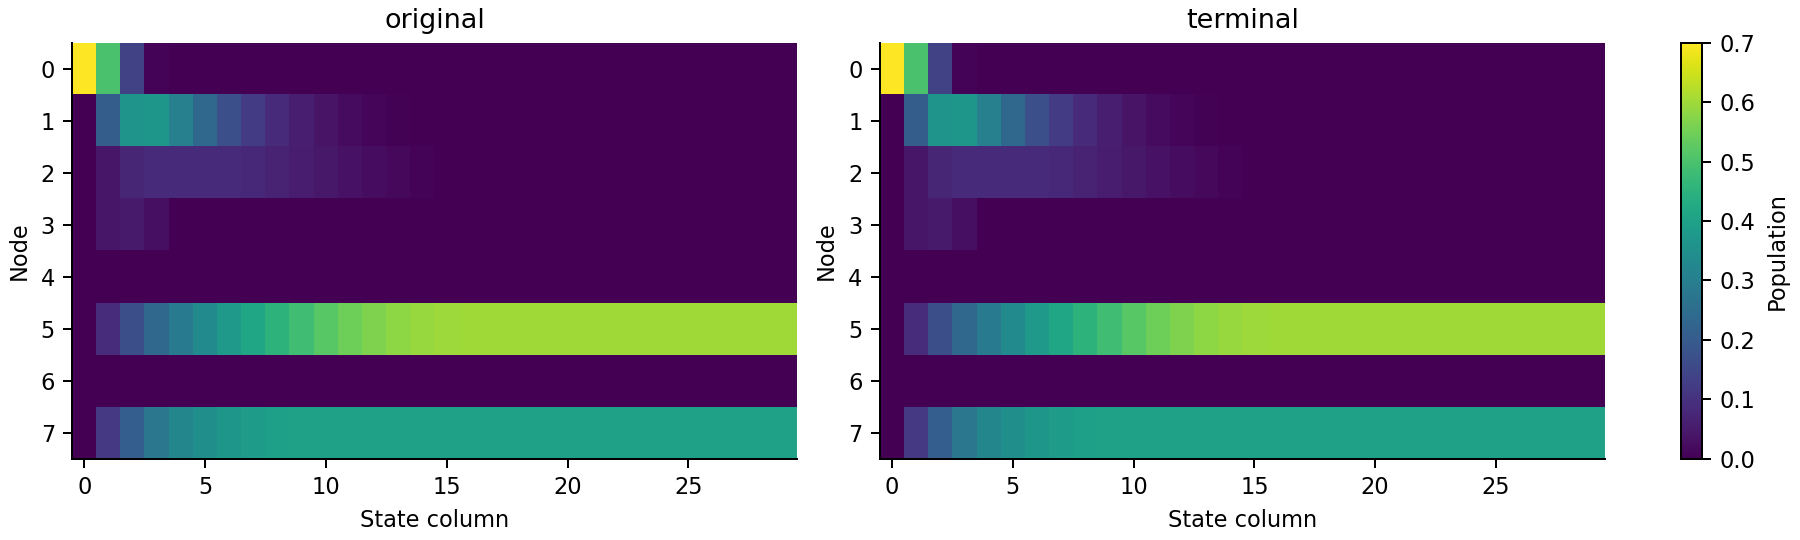

In [4]:
figure("evacuation_population")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.